# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** himlesh
- **Student ID:**023-24-0011
- **Section:** B
- **GitHub:** https://github.com/himleshsuthoor/k-mean-clustering
- **Kaggle:**
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42


### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [2]:
df = pd.read_csv('Mall_Customers.csv')
df.rename(columns={'Annual Income (k$)': 'Income', 'Spending Score (1-100)': 'Spending'}, inplace=True)
print('Shape:', df.shape)
print('Missing values:\n', df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Gender counts:\n', df['Gender'].value_counts())
print(df[['Age', 'Income', 'Spending']].describe())


Shape: (200, 5)
Missing values:
 CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64
Duplicate rows: 0
Gender counts:
 Gender
Female    112
Male       88
Name: count, dtype: int64
              Age      Income    Spending
count  200.000000  200.000000  200.000000
mean    38.850000   60.560000   50.200000
std     13.969007   26.264721   25.823522
min     18.000000   15.000000    1.000000
25%     28.750000   41.500000   34.750000
50%     36.000000   61.500000   50.000000
75%     49.000000   78.000000   73.000000
max     70.000000  137.000000   99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


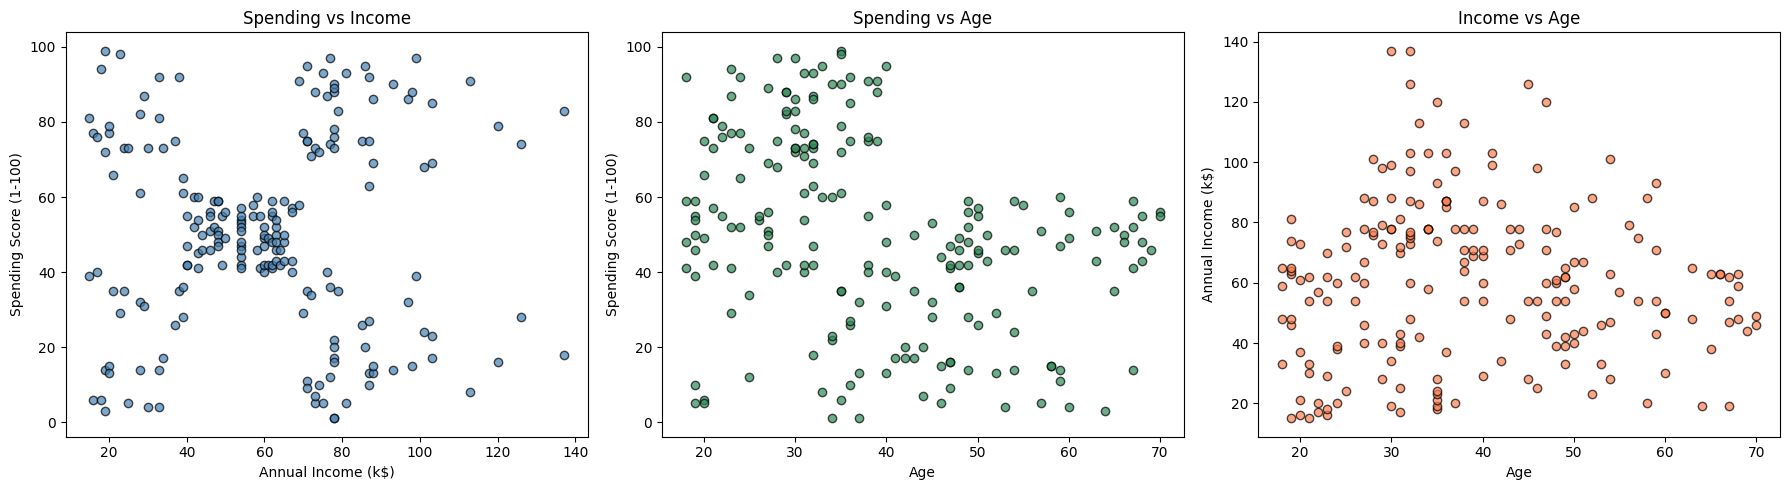

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(df['Income'], df['Spending'], c='steelblue', edgecolors='k', alpha=0.7)
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].set_title('Spending vs Income')

axes[1].scatter(df['Age'], df['Spending'], c='seagreen', edgecolors='k', alpha=0.7)
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Spending Score (1-100)')
axes[1].set_title('Spending vs Age')

axes[2].scatter(df['Age'], df['Income'], c='coral', edgecolors='k', alpha=0.7)
axes[2].set_xlabel('Age')
axes[2].set_ylabel('Annual Income (k$)')
axes[2].set_title('Income vs Age')

plt.tight_layout()
plt.show()


**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) In Spending vs Income, there are 5 clear groups (four corners and one center cluster). In Spending vs Age, there are about 2 to 3 loose groups that overlap heavily. In Income vs Age, the points are spread out without clear group separation. The Spending vs Income plot shows the groups most clearly.

(b) We cannot use accuracy or a train/test split because clustering is unsupervised learning with no ground truth labels. Without true labels, accuracy cannot be computed, and splitting data does not evaluate whether discovered groups represent natural structures.


---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [4]:
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])
centroids = np.array([4.0, 11.0])

it = 0
while True:
    it += 1
    dists = np.abs(x[:, None] - centroids[None, :])
    labels = dists.argmin(axis=1)
    print(f"Iteration {it}:")
    print("  Cluster 0:", x[labels == 0])
    print("  Cluster 1:", x[labels == 1])
    new_centroids = np.array([x[labels == 0].mean(), x[labels == 1].mean()])
    print(f"  New centroids: C0 = {new_centroids[0]:.2f}, C1 = {new_centroids[1]:.2f}")
    if np.allclose(new_centroids, centroids):
        break
    centroids = new_centroids

diff = x - centroids[labels]
inertia = np.sum(diff**2)
print(f"Final centroids: {centroids[0]:.2f}, {centroids[1]:.2f}")
print(f"Inertia: {inertia:.2f}")


Iteration 1:
  Cluster 0: [2 4 3]
  Cluster 1: [10 12 20 30 11 25]
  New centroids: C0 = 3.00, C1 = 18.00
Iteration 2:
  Cluster 0: [ 2  4 10  3]
  Cluster 1: [12 20 30 11 25]
  New centroids: C0 = 4.75, C1 = 19.60
Iteration 3:
  Cluster 0: [ 2  4 10 12  3 11]
  Cluster 1: [20 30 25]
  New centroids: C0 = 7.00, C1 = 25.00
Iteration 4:
  Cluster 0: [ 2  4 10 12  3 11]
  Cluster 1: [20 30 25]
  New centroids: C0 = 7.00, C1 = 25.00
Final centroids: 7.00, 25.00
Inertia: 150.00


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [5]:
pts = np.array([
    [185.0, 72.0],
    [170.0, 56.0],
    [168.0, 60.0],
    [179.0, 68.0],
    [182.0, 72.0],
    [188.0, 77.0]
])
centroids = np.copy(pts[:2])

d_p3_m2 = np.sqrt(np.sum((pts[2] - centroids[1])**2))
print(f"Iteration 1 check: d(P3, M2) = {d_p3_m2:.2f}")

it = 0
while True:
    it += 1
    diff = pts[:, None, :] - centroids[None, :, :]
    dists = np.sqrt(np.sum(diff**2, axis=2))
    labels = dists.argmin(axis=1)
    print(f"Iteration {it}:")
    for i in range(len(pts)):
        print(f"  P{i+1}: Cluster {labels[i]}")
    new_centroids = np.array([pts[labels == 0].mean(axis=0), pts[labels == 1].mean(axis=0)])
    print(f"  Centroids: C0 = {new_centroids[0]}, C1 = {new_centroids[1]}")
    if np.allclose(new_centroids, centroids):
        break
    centroids = new_centroids

final_diff = pts[:, None, :] - centroids[None, :, :]
final_dists = np.sqrt(np.sum(final_diff**2, axis=2))
print("Final distance table (rows P1-P6, cols C0, C1):")
print(np.round(final_dists, 2))


Iteration 1 check: d(P3, M2) = 4.47
Iteration 1:
  P1: Cluster 0
  P2: Cluster 1
  P3: Cluster 1
  P4: Cluster 0
  P5: Cluster 0
  P6: Cluster 0
  Centroids: C0 = [183.5   72.25], C1 = [169.  58.]
Iteration 2:
  P1: Cluster 0
  P2: Cluster 1
  P3: Cluster 1
  P4: Cluster 0
  P5: Cluster 0
  P6: Cluster 0
  Centroids: C0 = [183.5   72.25], C1 = [169.  58.]
Final distance table (rows P1-P6, cols C0, C1):
[[ 1.52 21.26]
 [21.13  2.24]
 [19.76  2.24]
 [ 6.19 14.14]
 [ 1.52 19.1 ]
 [ 6.54 26.87]]


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [6]:
def my_kmeans(X, init_centroids, max_iter=100):
    X = np.asarray(X, dtype=float)
    centroids = np.array(init_centroids, dtype=float).copy()
    k = len(centroids)
    n_iter = 0
    for it in range(max_iter):
        n_iter += 1
        diff = X[:, None, :] - centroids[None, :, :]
        dists = np.sum(diff**2, axis=2)
        labels = np.argmin(dists, axis=1)
        
        new_centroids = np.copy(centroids)
        for c in range(k):
            members = X[labels == c]
            if len(members) > 0:
                new_centroids[c] = np.mean(members, axis=0)
        
        if np.allclose(new_centroids, centroids):
            break
        centroids = new_centroids
        
    diff = X - centroids[labels]
    inertia = np.sum(diff**2)
    return labels, centroids, inertia, n_iter


In [7]:
ex1_data = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25]).reshape(-1, 1)
ex1_init = np.array([4.0, 11.0]).reshape(-1, 1)

labels, centroids, inertia, n_iter = my_kmeans(ex1_data, ex1_init)
print("Final centroids:", centroids.ravel())
print("Inertia:", inertia)
print("Iterations:", n_iter)


Final centroids: [ 7. 25.]
Inertia: 150.0
Iterations: 4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [8]:
X2 = df[['Income', 'Spending']].values
init_5 = X2[:5].copy()

my_labels, my_centroids, my_inertia, my_iter = my_kmeans(X2, init_5)

sk_km = KMeans(n_clusters=5, init=init_5, n_init=1, tol=0, algorithm='lloyd')
sk_km.fit(X2)

print("Iterations - Custom:", my_iter, "| Scikit-learn:", sk_km.n_iter_)
print(f"Inertia - Custom: {my_inertia:.4f} | Scikit-learn: {sk_km.inertia_:.4f}")
print("Labels match exactly:", np.array_equal(my_labels, sk_km.labels_))
print("Centroids match:", np.allclose(my_centroids, sk_km.cluster_centers_))
print("Final Centroids:\n", np.round(my_centroids, 2))


Iterations - Custom: 4 | Scikit-learn: 4
Inertia - Custom: 44448.4554 | Scikit-learn: 44448.4554
Labels match exactly: True
Centroids match: True
Final Centroids:
 [[26.3  20.91]
 [25.73 79.36]
 [88.2  17.11]
 [86.54 82.13]
 [55.3  49.52]]


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a) In iteration 1, the starting centroids were 4 and 11. Point 10 was closer to 11 (|10 - 11| = 1 vs |10 - 4| = 6), so it was placed in C2. After recalculating, C1 became 3.0 and C2 became 18.0. In iteration 2, the distance from 10 to C1 was |10 - 3.0| = 7.0 and to C2 was |10 - 18.0| = 8.0. Because 7.0 is smaller than 8.0, point 10 was closer to C1 and moved to C1.

(b) The loop stops when centroids do not change between consecutive iterations (convergence). Stopping is guaranteed because there are finitely many possible cluster assignments, and each step either strictly decreases or maintains inertia. It can still stop in a local minimum because it makes greedy assignments.

(c) Yes, my custom function matched scikit-learn exactly in labels, centroids, inertia (44448.46), and iterations (4).

(d) A centroid is the average point representing the center of that customer group (mean income and mean spending score). Features must be numeric because K-Means computes distances and arithmetic means, which cannot be directly calculated on text or categories.


---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


 K       Inertia  Silhouette
 2 181363.595960    0.296897
 3 106348.373062    0.467614
 4  73679.789039    0.493196
 5  44448.455448    0.553932
 6  37442.247450    0.536756
 7  30566.451130    0.532171
 8  25079.766962    0.453649
 9  21850.165283    0.456508
10  19755.619861    0.441621
K with highest silhouette: 5 (Score: 0.5539)


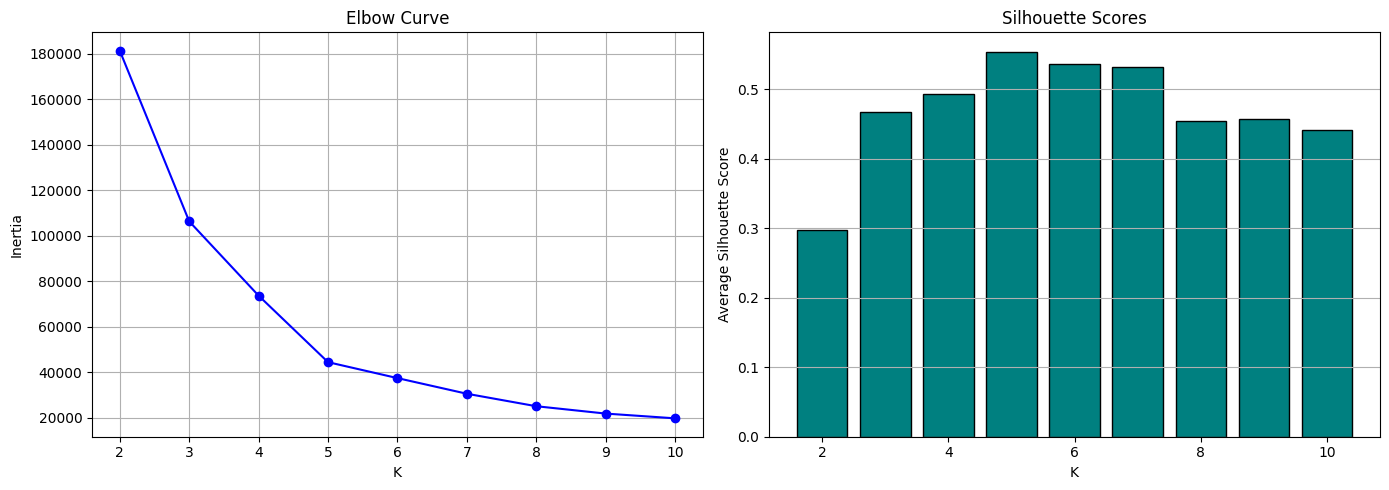

In [9]:
k_values = list(range(2, 11))
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    km.fit(X2)
    inertias.append(km.inertia_)
    sil = silhouette_score(X2, km.labels_)
    silhouettes.append(sil)

results_df = pd.DataFrame({'K': k_values, 'Inertia': inertias, 'Silhouette': silhouettes})
print(results_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_values, inertias, marker='o', color='b')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Curve')
axes[0].grid(True)

axes[1].bar(k_values, silhouettes, color='teal', edgecolor='k')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Average Silhouette Score')
axes[1].set_title('Silhouette Scores')
axes[1].grid(True, axis='y')

plt.tight_layout()
plt.show()

best_k = k_values[np.argmax(silhouettes)]
print(f"K with highest silhouette: {best_k} (Score: {max(silhouettes):.4f})")


### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [10]:
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
labels5 = km5.labels_

def hand_silhouette(X, labels, idx):
    X = np.asarray(X, dtype=float)
    n = len(X)
    c_i = labels[idx]
    same_idx = [i for i in range(n) if labels[i] == c_i and i != idx]
    if len(same_idx) == 0:
        a = 0.0
    else:
        a = np.mean([np.linalg.norm(X[idx] - X[i]) for i in same_idx])
        
    other_clusters = [c for c in np.unique(labels) if c != c_i]
    b = min([np.mean([np.linalg.norm(X[idx] - X[i]) for i in range(n) if labels[i] == c]) for c in other_clusters])
    s = (b - a) / max(a, b)
    return a, b, s

a0, b0, s0 = hand_silhouette(X2, labels5, 0)
sk_sil = silhouette_samples(X2, labels5)
print(f"Customer 1 (Row 0): a = {a0:.4f}, b = {b0:.4f}, hand s = {s0:.4f}")
print(f"silhouette_samples value: {sk_sil[0]:.4f}")

cluster_stats = []
for c in range(5):
    c_vals = sk_sil[labels5 == c]
    cluster_stats.append({
        'Cluster': c,
        'Count': len(c_vals),
        'Mean Silhouette': c_vals.mean(),
        'Min Silhouette': c_vals.min()
    })
print(pd.DataFrame(cluster_stats).to_string(index=False))
print("Customers with negative silhouette:", np.sum(sk_sil < 0))


Customer 1 (Row 0): a = 24.6404, b = 42.2653, hand s = 0.4170
silhouette_samples value: 0.4170
 Cluster  Count  Mean Silhouette  Min Silhouette
       0     22         0.599013        0.050721
       1     35         0.503987       -0.023381
       2     23         0.512268       -0.009278
       3     81         0.596651        0.115294
       4     39         0.509171        0.225413
Customers with negative silhouette: 2


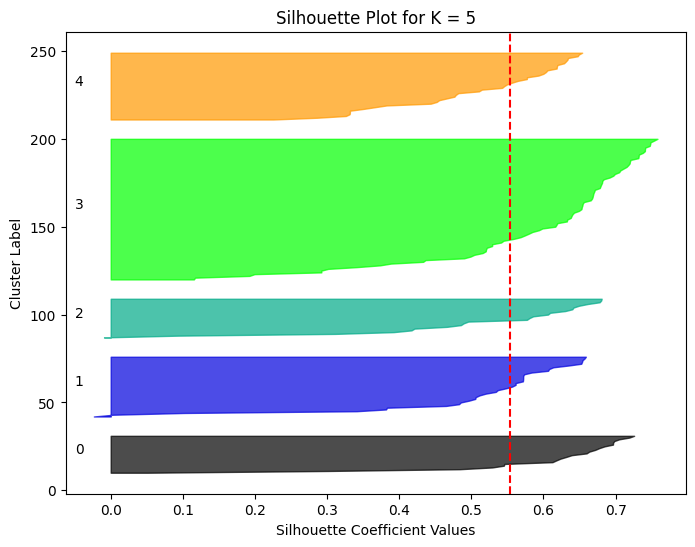

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
y_lower = 10
for c in range(5):
    c_vals = sk_sil[labels5 == c]
    c_vals.sort()
    size_c = len(c_vals)
    y_upper = y_lower + size_c
    color = plt.cm.nipy_spectral(float(c) / 5)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, c_vals, facecolor=color, edgecolor=color, alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * size_c, str(c))
    y_lower = y_upper + 10

avg_sil = silhouette_score(X2, labels5)
ax.axvline(x=avg_sil, color="red", linestyle="--")
ax.set_xlabel("Silhouette Coefficient Values")
ax.set_ylabel("Cluster Label")
ax.set_title("Silhouette Plot for K = 5")
plt.show()


### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [12]:
pts_pract = np.array([1, 3, 5, 7, 11, 13, 15]).reshape(-1, 1)
init_pract = np.array([1.0, 11.0]).reshape(-1, 1)

pract_labels, pract_centroids, pract_inertia, pract_iter = my_kmeans(pts_pract, init_pract)
print("Final clusters:", pract_labels)
print("Final centroids:", pract_centroids.ravel())
print("Iterations:", pract_iter)

sk_pract_sil = silhouette_samples(pts_pract, pract_labels)
points_to_check = [(1, 0), (7, 3), (11, 4)]
for val, idx in points_to_check:
    a, b, s = hand_silhouette(pts_pract, pract_labels, idx)
    print(f"Point {val} (idx {idx}): a = {a:.4f}, b = {b:.4f}, hand s = {s:.4f}, sklearn s = {sk_pract_sil[idx]:.4f}")


Final clusters: [0 0 0 0 1 1 1]
Final centroids: [ 4. 13.]
Iterations: 3
Point 1 (idx 0): a = 4.0000, b = 12.0000, hand s = 0.6667, sklearn s = 0.6667
Point 7 (idx 3): a = 4.0000, b = 6.0000, hand s = 0.3333, sklearn s = 0.3333
Point 11 (idx 4): a = 3.0000, b = 7.0000, hand s = 0.5714, sklearn s = 0.5714


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a) The elbow curve shows a sharp bend at K = 5. The inertia drops by 29,231.33 going from K = 4 to 5 (73,679.79 to 44,448.46), and then drops by only 7,006.21 from K = 5 to 6 (44,448.46 to 37,442.25). The silhouette score also peaks at K = 5 with 0.5539. Both methods agree on K = 5.

(b) The silhouette of customer 1 is 0.4170. This positive score shows that customer 1 is well assigned to its cluster. Cluster 1 has the weakest average silhouette (0.5040, min -0.0234). Across the entire dataset, only 2 customers have a negative silhouette.

(c) Point 7 is less well placed than point 1. Point 1 has a = 4.0, b = 12.0, giving s = 0.6667. Point 7 has a = 4.0, b = 6.0, giving s = 0.3333. Because point 7 is much closer to the other cluster (b = 6.0 vs 12.0), it sits near the decision boundary.

(d) We should never choose K only by lowest inertia because inertia decreases continuously as K grows and reaches zero when K equals the number of samples, which produces meaningless clusters.


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


                    Setting  Distinct Inertias       Lowest      Highest     % Best
    init='random', n_init=1                  9 44448.455448 76443.903219  40.000000
 init='k-means++', n_init=1                  8 44448.455448 67859.584908  63.333333
init='k-means++', n_init=10                  1 44448.455448 44448.455448 100.000000


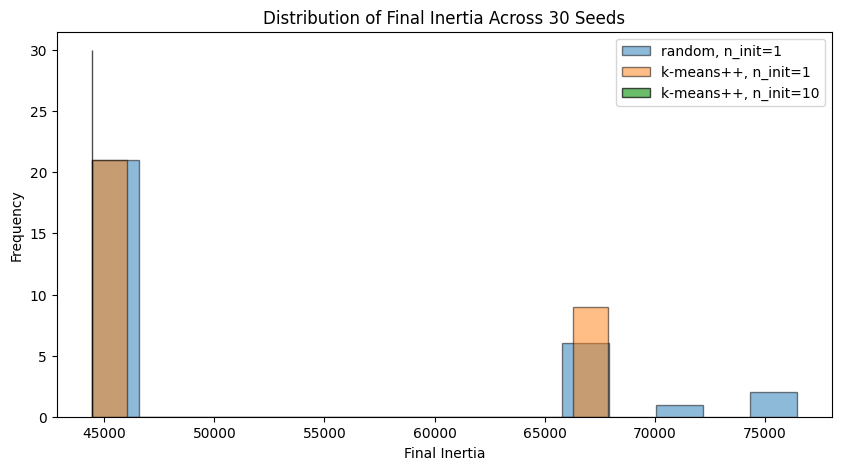

In [13]:
def run_30_seeds(init_method, n_init_val):
    inertias = []
    for s in range(30):
        km = KMeans(n_clusters=5, init=init_method, n_init=n_init_val, random_state=s)
        km.fit(X2)
        inertias.append(km.inertia_)
    return np.array(inertias)

inr_rand1 = run_30_seeds('random', 1)
inr_pp1 = run_30_seeds('k-means++', 1)
inr_pp10 = run_30_seeds('k-means++', 10)

best_inr = 44448.5

rows = []
for name, arr in [("init='random', n_init=1", inr_rand1),
                  ("init='k-means++', n_init=1", inr_pp1),
                  ("init='k-means++', n_init=10", inr_pp10)]:
    rounded = np.round(arr, 1)
    distinct = len(np.unique(rounded))
    lowest = np.min(arr)
    highest = np.max(arr)
    pct_best = np.mean(np.isclose(arr, best_inr, atol=1.0)) * 100
    rows.append({'Setting': name, 'Distinct Inertias': distinct, 'Lowest': lowest, 'Highest': highest, '% Best': pct_best})

print(pd.DataFrame(rows).to_string(index=False))

plt.figure(figsize=(10, 5))
plt.hist(inr_rand1, bins=15, alpha=0.5, label="random, n_init=1", edgecolor='k')
plt.hist(inr_pp1, bins=15, alpha=0.5, label="k-means++, n_init=1", edgecolor='k')
plt.hist(inr_pp10, bins=5, alpha=0.7, label="k-means++, n_init=10", edgecolor='k')
plt.xlabel("Final Inertia")
plt.ylabel("Frequency")
plt.title("Distribution of Final Inertia Across 30 Seeds")
plt.legend()
plt.show()


### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


Best run (Seed 0): Inertia = 44448.46
Worst run (Seed 1): Inertia = 76443.90
ARI between best and worst: 0.7990


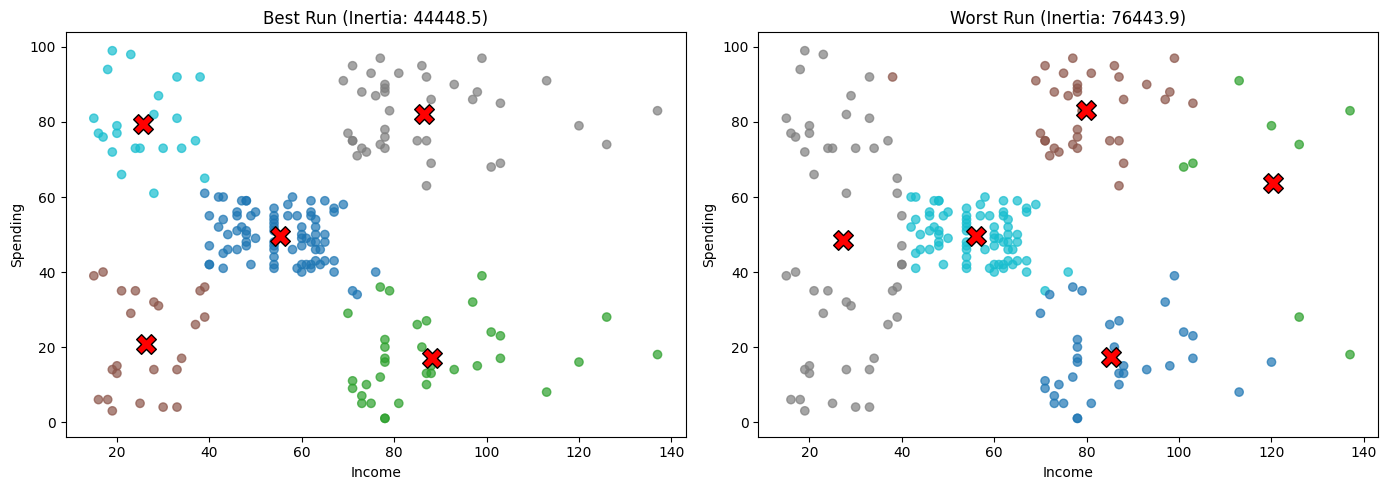

In [14]:
best_seed = int(np.argmin(inr_rand1))
worst_seed = int(np.argmax(inr_rand1))

km_best = KMeans(n_clusters=5, init='random', n_init=1, random_state=best_seed).fit(X2)
km_worst = KMeans(n_clusters=5, init='random', n_init=1, random_state=worst_seed).fit(X2)

print(f"Best run (Seed {best_seed}): Inertia = {km_best.inertia_:.2f}")
print(f"Worst run (Seed {worst_seed}): Inertia = {km_worst.inertia_:.2f}")
print(f"ARI between best and worst: {adjusted_rand_score(km_best.labels_, km_worst.labels_):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X2[:, 0], X2[:, 1], c=km_best.labels_, cmap='tab10', alpha=0.7)
axes[0].scatter(km_best.cluster_centers_[:, 0], km_best.cluster_centers_[:, 1], c='red', marker='X', s=200, edgecolors='k')
axes[0].set_title(f"Best Run (Inertia: {km_best.inertia_:.1f})")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Spending")

axes[1].scatter(X2[:, 0], X2[:, 1], c=km_worst.labels_, cmap='tab10', alpha=0.7)
axes[1].scatter(km_worst.cluster_centers_[:, 0], km_worst.cluster_centers_[:, 1], c='red', marker='X', s=200, edgecolors='k')
axes[1].set_title(f"Worst Run (Inertia: {km_worst.inertia_:.1f})")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Spending")

plt.tight_layout()
plt.show()


**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a) The random-start setting produced 9 distinct inertia values and reached the best inertia only 40.0% of the time. In contrast, k-means++ with n_init=1 produced 8 distinct values and reached the best inertia 63.3% of the time. k-means++ with n_init=10 produced only 1 distinct inertia value and reached the best inertia 100.0% of the time.

(b) Different random seeds pick different initial centroids. Since K-Means uses greedy optimization, starting in a poor location traps the algorithm in a local minimum with higher inertia.

(c) k-means++ spreads starting centroids far apart to avoid bad starting points. Increasing n_init runs multiple restarts and picks the one with the lowest inertia. In my table, n_init=10 achieved a 100.0% success rate, always finding the global minimum (44448.5).

(d) ARI is used because cluster numbers are arbitrary. One run might label a group cluster 0 while another calls it cluster 4. ARI compares whether pairs of items are grouped together or separated, regardless of the numeric labels.


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


ARI raw k$ vs raw dollars: 0.5070
ARI scaled k$ vs scaled dollars: 1.0000
ARI raw dollars vs scaled dollars: 0.3605


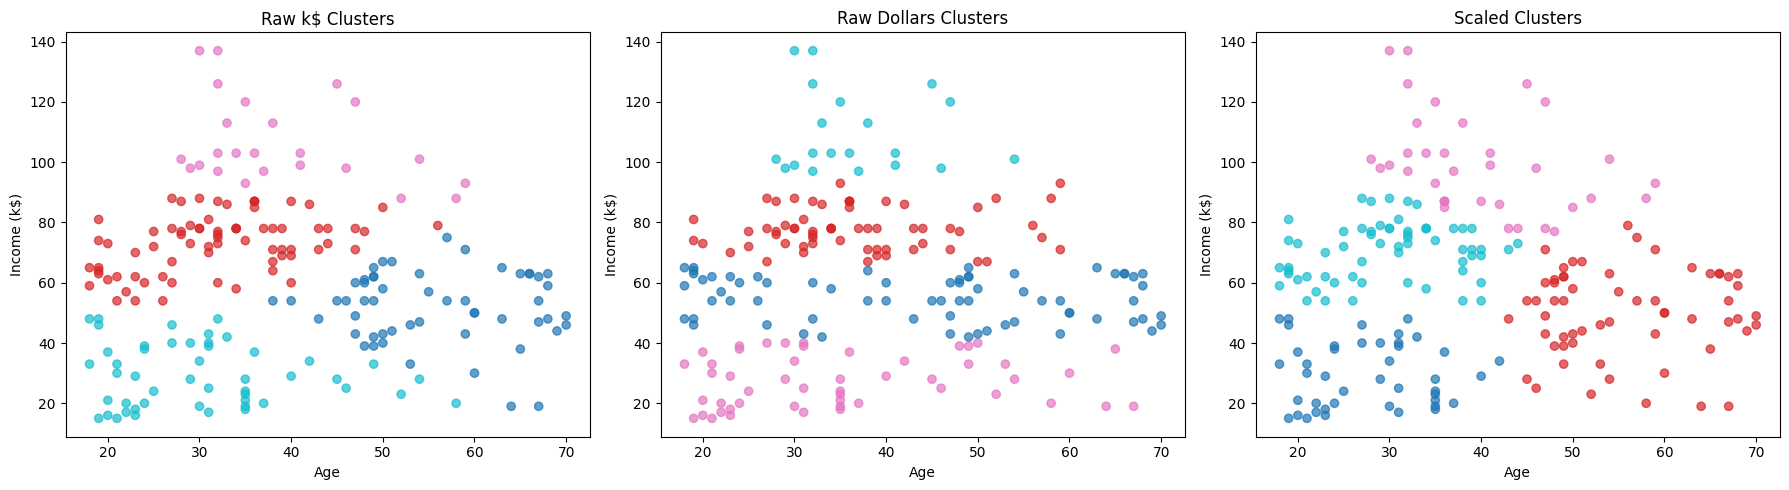

In [15]:
X_age_inc_k = df[['Age', 'Income']].values.astype(float)
X_age_inc_d = X_age_inc_k.copy()
X_age_inc_d[:, 1] *= 1000

scaler = StandardScaler()
X_age_inc_k_s = scaler.fit_transform(X_age_inc_k)
X_age_inc_d_s = scaler.fit_transform(X_age_inc_d)

c_raw_k = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(X_age_inc_k)
c_raw_d = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(X_age_inc_d)
c_s_k = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(X_age_inc_k_s)
c_s_d = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(X_age_inc_d_s)

print(f"ARI raw k$ vs raw dollars: {adjusted_rand_score(c_raw_k, c_raw_d):.4f}")
print(f"ARI scaled k$ vs scaled dollars: {adjusted_rand_score(c_s_k, c_s_d):.4f}")
print(f"ARI raw dollars vs scaled dollars: {adjusted_rand_score(c_raw_d, c_s_d):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(df['Age'], df['Income'], c=c_raw_k, cmap='tab10', alpha=0.7)
axes[0].set_title("Raw k$ Clusters")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Income (k$)")

axes[1].scatter(df['Age'], df['Income'], c=c_raw_d, cmap='tab10', alpha=0.7)
axes[1].set_title("Raw Dollars Clusters")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Income (k$)")

axes[2].scatter(df['Age'], df['Income'], c=c_s_k, cmap='tab10', alpha=0.7)
axes[2].set_title("Scaled Clusters")
axes[2].set_xlabel("Age")
axes[2].set_ylabel("Income (k$)")

plt.tight_layout()
plt.show()


### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [16]:
wine = load_wine()
X_wine = wine.data
y_wine = wine.target

stds = np.std(X_wine, axis=0)
feat_names = wine.feature_names
sorted_idx = np.argsort(stds)
print(f"Smallest std: {feat_names[sorted_idx[0]]} ({stds[sorted_idx[0]]:.4f})")
print("Three largest stds:")
for i in sorted_idx[-3:][::-1]:
    print(f"  {feat_names[i]}: {stds[i]:.2f}")


Smallest std: nonflavanoid_phenols (0.1241)
Three largest stds:
  proline: 314.02
  magnesium: 14.24
  alcalinity_of_ash: 3.33


In [17]:
km_wine_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_wine)
X_wine_scaled = StandardScaler().fit_transform(X_wine)
km_wine_scaled = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_wine_scaled)

print("Raw Wine Data:")
print(f"  ARI against true cultivar: {adjusted_rand_score(y_wine, km_wine_raw.labels_):.4f}")
print(f"  Silhouette score: {silhouette_score(X_wine, km_wine_raw.labels_):.4f}")
print(f"  Cluster sizes: {np.bincount(km_wine_raw.labels_)}")

print("Scaled Wine Data:")
print(f"  ARI against true cultivar: {adjusted_rand_score(y_wine, km_wine_scaled.labels_):.4f}")
print(f"  Silhouette score: {silhouette_score(X_wine_scaled, km_wine_scaled.labels_):.4f}")
print(f"  Cluster sizes: {np.bincount(km_wine_scaled.labels_)}")


Raw Wine Data:
  ARI against true cultivar: 0.3711
  Silhouette score: 0.5711
  Cluster sizes: [62 47 69]
Scaled Wine Data:
  ARI against true cultivar: 0.8975
  Silhouette score: 0.2849
  Cluster sizes: [65 51 62]


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


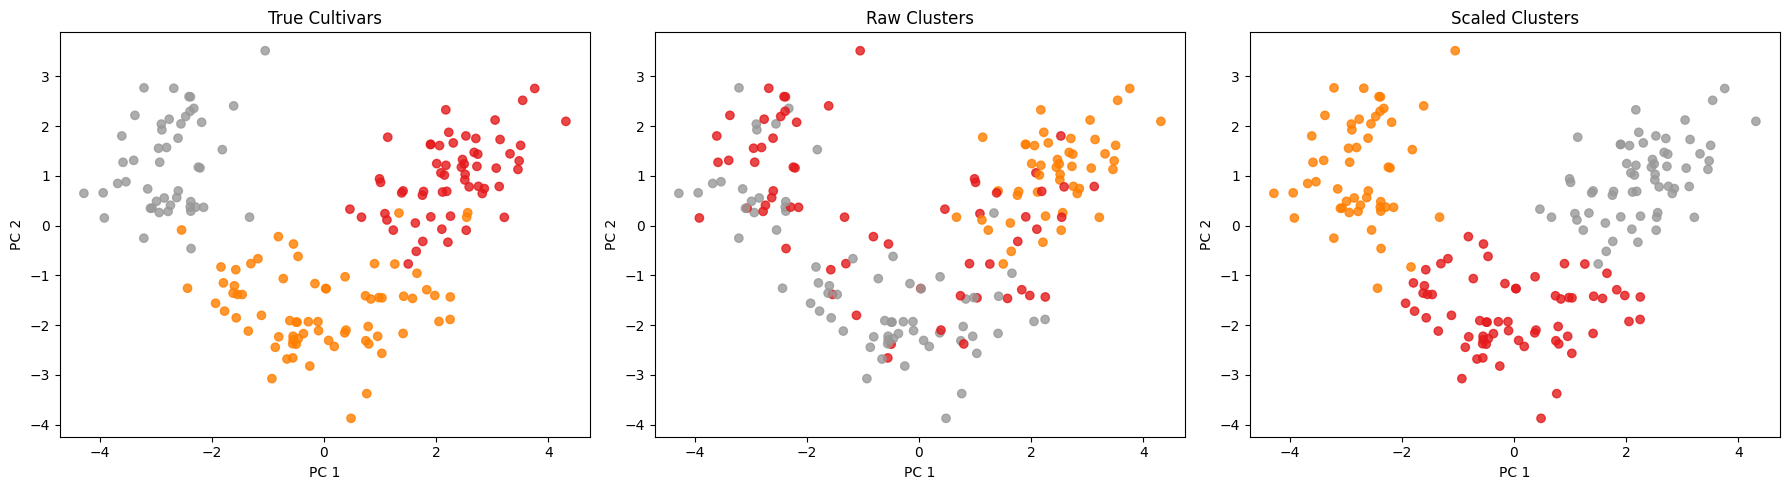

In [18]:
pca = PCA(n_components=2)
X_wine_pca = pca.fit_transform(X_wine_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=y_wine, cmap='Set1', alpha=0.8)
axes[0].set_title("True Cultivars")
axes[0].set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")

axes[1].scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=km_wine_raw.labels_, cmap='Set1', alpha=0.8)
axes[1].set_title("Raw Clusters")
axes[1].set_xlabel("PC 1")
axes[1].set_ylabel("PC 2")

axes[2].scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=km_wine_scaled.labels_, cmap='Set1', alpha=0.8)
axes[2].set_title("Scaled Clusters")
axes[2].set_xlabel("PC 1")
axes[2].set_ylabel("PC 2")

plt.tight_layout()
plt.show()


**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a) Multiplying Income by 1000 changed the clusters completely (ARI dropped to 0.5070). In Euclidean distance, squared income differences became a million times larger than squared age differences, so Income completely dominated the distance and Age was ignored.

(b) Proline dominated the raw distance. Its standard deviation is 314.02, while the next largest is magnesium (14.24) and the smallest is nonflavanoid phenols (0.12). The ARI on raw data was only 0.3711, but on scaled data it jumped to 0.8975.

(c) The silhouette was higher on raw data (0.5711 vs 0.2849) because proline spread points out widely along one axis, making points look artificially separated. Comparing silhouette scores between raw and scaled data is not fair because distances are calculated in different metric spaces.

(d) Scale features whenever they are measured in different units or have very different ranges. Only leave them unscaled if all features share the exact same physical unit and natural variance represents true importance.


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [19]:
extra_customer = np.array([[400.0, 99.0]])
X2_ext = np.vstack([X2, extra_customer])

km_orig = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2)
km_ext = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_ext)

print("Cluster sizes without outlier:", np.bincount(km_orig.labels_))
print("Cluster sizes with outlier:", np.bincount(km_ext.labels_))
print("\nCentroids without outlier (sorted by income):")
print(np.round(km_orig.cluster_centers_[np.argsort(km_orig.cluster_centers_[:, 0])], 2))
print("\nCentroids with outlier (sorted by income):")
print(np.round(km_ext.cluster_centers_[np.argsort(km_ext.cluster_centers_[:, 0])], 2))

ari_outlier = adjusted_rand_score(km_orig.labels_, km_ext.labels_[:200])
print(f"\nARI on original 200 customers: {ari_outlier:.4f}")


Cluster sizes without outlier: [22 35 23 81 39]
Cluster sizes with outlier: [100   1  23  38  39]

Centroids without outlier (sorted by income):
[[25.73 79.36]
 [26.3  20.91]
 [55.3  49.52]
 [86.54 82.13]
 [88.2  17.11]]

Centroids with outlier (sorted by income):
[[ 26.3   20.91]
 [ 48.26  56.48]
 [ 86.54  82.13]
 [ 87.    18.63]
 [400.    99.  ]]

ARI on original 200 customers: 0.7532


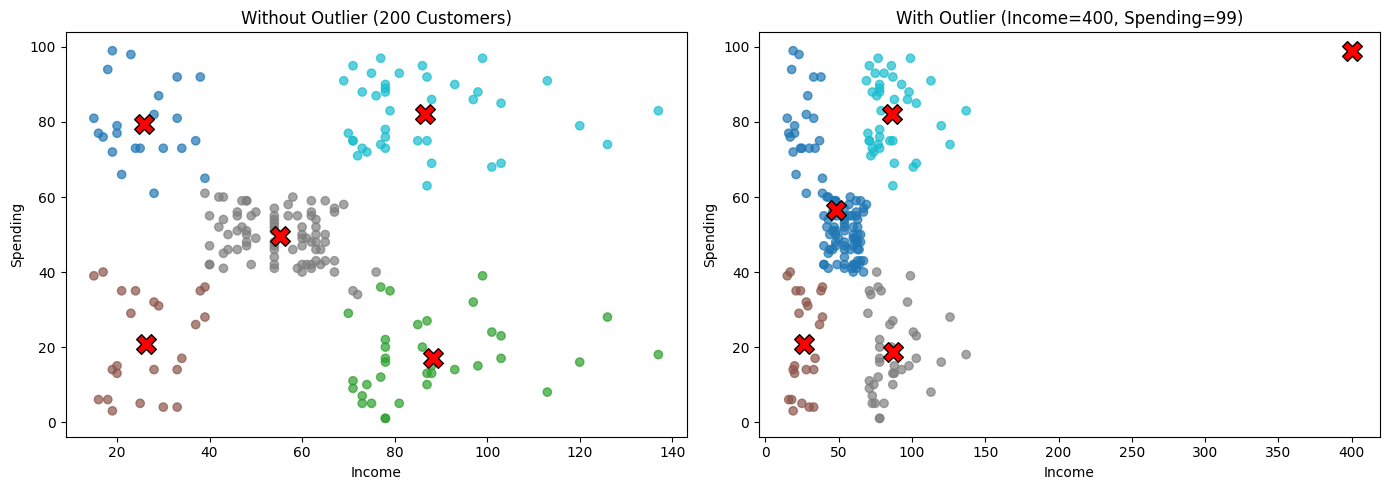

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X2[:, 0], X2[:, 1], c=km_orig.labels_, cmap='tab10', alpha=0.7)
axes[0].scatter(km_orig.cluster_centers_[:, 0], km_orig.cluster_centers_[:, 1], c='red', marker='X', s=200, edgecolors='k')
axes[0].set_title("Without Outlier (200 Customers)")
axes[0].set_xlabel("Income")
axes[0].set_ylabel("Spending")

axes[1].scatter(X2_ext[:, 0], X2_ext[:, 1], c=km_ext.labels_, cmap='tab10', alpha=0.7)
axes[1].scatter(km_ext.cluster_centers_[:, 0], km_ext.cluster_centers_[:, 1], c='red', marker='X', s=200, edgecolors='k')
axes[1].set_title("With Outlier (Income=400, Spending=99)")
axes[1].set_xlabel("Income")
axes[1].set_ylabel("Spending")

plt.tight_layout()
plt.show()


### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [21]:
dists_orig = km_orig.transform(X2).min(axis=1)
dist_ext = km_orig.transform(extra_customer).min()
mean_d = dists_orig.mean()
std_d = dists_orig.std()
thresh = mean_d + 3 * std_d

print(f"Distance threshold (mean + 3*std): {thresh:.2f}")
print(f"Extra customer distance: {dist_ext:.2f} | Flagged: {dist_ext > thresh}")
flagged_indices = np.where(dists_orig > thresh)[0]
print(f"Real customers flagged: {len(flagged_indices)} (indices: {flagged_indices})")

farthest_5 = np.argsort(dists_orig)[-5:][::-1]
farthest_table = df.iloc[farthest_5][['CustomerID', 'Age', 'Income', 'Spending']].copy()
farthest_table['Cluster'] = km_orig.labels_[farthest_5]
farthest_table['Distance'] = dists_orig[farthest_5]
print("\nTop 5 farthest real customers:")
print(farthest_table.to_string(index=False))

clean_mask = dists_orig <= thresh
X2_clean = X2[clean_mask]
km_clean = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X2_clean)

print(f"\nClean model cluster sizes: {np.bincount(km_clean.labels_)}")
pred_200 = km_clean.predict(X2)
print(f"ARI clean model vs original on 200 customers: {adjusted_rand_score(km_orig.labels_, pred_200):.4f}")


Distance threshold (mean + 3*std): 34.80
Extra customer distance: 313.92 | Flagged: True
Real customers flagged: 4 (indices: [196 197 198 199])

Top 5 farthest real customers:
 CustomerID  Age  Income  Spending  Cluster  Distance
        200   30     137        83        4 50.469069
        199   32     137        18        1 48.808037
        198   32     126        74        4 40.289958
        197   45     126        28        1 39.336227
        196   35     120        79        4 33.607443

Clean model cluster sizes: [22 37 23 80 34]
ARI clean model vs original on 200 customers: 0.9847


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a) The single extreme customer created a cluster of size 1 with centroid [400, 99]. This left only 4 clusters for the remaining 200 customers, merging two real groups into one large cluster of 100 points and dropping the ARI to 0.7532.

(b) The distance rule flagged the outlier easily (distance 313.92 vs threshold 34.80). It also flagged 4 real customers (IDs 197, 198, 199, 200) with incomes of 126k$ to 137k$. These are not errors; they are genuine high-income customers at the outer edge of the data.

(c) Two ways to handle outliers are capping extreme values (winsorization) or using density algorithms like DBSCAN. The main risk of deleting them is losing genuine, highly valuable customers like top earners.


---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [22]:
df['Cluster'] = km_orig.labels_

profile = df.groupby('Cluster').agg(
    Count=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Income', 'mean'),
    Mean_Spending=('Spending', 'mean'),
    Pct_Female=('Gender', lambda g: (g == 'Female').mean() * 100)
).sort_values(by='Mean_Income')

print(profile.round(2))


         Count  Mean_Age  Mean_Income  Mean_Spending  Pct_Female
Cluster                                                         
0           22     25.27        25.73          79.36       59.09
2           23     45.22        26.30          20.91       60.87
3           81     42.72        55.30          49.52       59.26
4           39     32.69        86.54          82.13       53.85
1           35     41.11        88.20          17.11       45.71


In [23]:
def assign_segment(inc, sp):
    if inc < 40:
        inc_label = "Low Income"
    elif inc >= 70:
        inc_label = "High Income"
    else:
        inc_label = "Mid Income"
        
    if sp < 35:
        sp_label = "Low Spending"
    elif sp >= 65:
        sp_label = "High Spending"
    else:
        sp_label = "Mid Spending"
        
    return f"{inc_label} / {sp_label}"

cluster_to_segment = {c: assign_segment(profile.loc[c, 'Mean_Income'], profile.loc[c, 'Mean_Spending']) for c in profile.index}
df['Segment'] = df['Cluster'].map(cluster_to_segment)

print("Segment sizes:")
print(df['Segment'].value_counts())


Segment sizes:
Segment
Mid Income / Mid Spending      81
High Income / High Spending    39
High Income / Low Spending     35
Low Income / Low Spending      23
Low Income / High Spending     22
Name: count, dtype: int64


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [24]:
print(f"Overall % Female: {(df['Gender'] == 'Female').mean() * 100:.2f}%\n")
pct_female_seg = df.groupby('Segment')['Gender'].apply(lambda g: (g == 'Female').mean() * 100)
print(pct_female_seg.round(2))

X3 = df[['Age', 'Income', 'Spending']].values
X3_scaled = StandardScaler().fit_transform(X3)

print("\nAverage silhouette for K = 2 to 8 (Age, Income, Spending):")
for k in range(2, 9):
    km_3f = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X3_scaled)
    print(f"  K = {k}: Silhouette = {silhouette_score(X3_scaled, km_3f.labels_):.4f}")


Overall % Female: 56.00%

Segment
High Income / High Spending    53.85
High Income / Low Spending     45.71
Low Income / High Spending     59.09
Low Income / Low Spending      60.87
Mid Income / Mid Spending      59.26
Name: Gender, dtype: float64

Average silhouette for K = 2 to 8 (Age, Income, Spending):
  K = 2: Silhouette = 0.3355
  K = 3: Silhouette = 0.3578
  K = 4: Silhouette = 0.4040
  K = 5: Silhouette = 0.4166
  K = 6: Silhouette = 0.4269
  K = 7: Silhouette = 0.4181
  K = 8: Silhouette = 0.4277


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [25]:
sil_3f = [silhouette_score(X3_scaled, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X3_scaled)) for k in range(2, 9)]
best_k_3f = list(range(2, 9))[np.argmax(sil_3f)]
print(f"Best K: {best_k_3f} (Silhouette: {max(sil_3f):.4f})")

km_best_3f = KMeans(n_clusters=best_k_3f, n_init=10, random_state=SEED).fit(X3_scaled)
df['Cluster_3F'] = km_best_3f.labels_

profile_3f = df.groupby('Cluster_3F').agg(
    Count=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Income', 'mean'),
    Mean_Spending=('Spending', 'mean')
).sort_values(by='Mean_Age')

print("\n3-Feature Profile Table (sorted by Age):")
print(profile_3f.round(2))

ari_2f_3f = adjusted_rand_score(df['Cluster'], df['Cluster_3F'])
print(f"\nARI between 2-feature K=5 and 3-feature K={best_k_3f}: {ari_2f_3f:.4f}")


Best K: 8 (Silhouette: 0.4277)

3-Feature Profile Table (sorted by Age):
            Count  Mean_Age  Mean_Income  Mean_Spending
Cluster_3F                                             
3              32     24.75        55.78          49.50
0              22     25.27        25.73          79.36
5              39     32.69        86.54          82.13
7              11     34.09        23.55          25.45
1              32     41.00        89.41          15.59
6              34     47.38        56.88          47.09
2              10     55.20        26.90          13.00
4              20     64.85        53.15          49.85

ARI between 2-feature K=5 and 3-feature K=8: 0.6066


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a) 
1. Low Income / Low Spending (Count 23, Age 45.2, Income 26.3k$, Spending 20.9): Budget Conscious. Action: Send discount coupons on essential items.
2. Low Income / High Spending (Count 22, Age 25.3, Income 25.7k$, Spending 79.4): Trend Seekers. Action: Offer student discounts and flash fashion sales.
3. Mid Income / Mid Spending (Count 81, Age 42.7, Income 55.3k$, Spending 49.5): Core Regulars. Action: Enroll in a standard mall rewards program.
4. High Income / Low Spending (Count 35, Age 41.1, Income 88.2k$, Spending 17.1): Careful Savers. Action: Promote high-quality investment products and exclusive previews.
5. High Income / High Spending (Count 39, Age 32.7, Income 86.5k$, Spending 82.1): VIP Shoppers. Action: Invite to private VIP lounge events and personal styling.

(b) VIP Shoppers (High Income / High Spending) is the most valuable now because they spend the most (82.1) and have high income (86.5k$). Careful Savers (High Income / Low Spending) is the biggest opportunity because they have high income (88.2k$) but spend very little (17.1).

(c) No, Gender does not separate the segments. Female percentage stays between 45.7% and 60.9% across all five segments, close to the overall average of 56.0%.

(d) Adding Age splits the middle group into younger and older groups, but makes the clustering harder to explain. I would present the 2-feature model because it produces 5 clear, actionable groups based directly on purchasing behavior.


---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [26]:
output_df = df[['CustomerID', 'Age', 'Gender', 'Income', 'Spending', 'Cluster', 'Segment']]
output_df.to_csv('customer_segments.csv', index=False)
print("Saved customer_segments.csv successfully.")
print("\nCustomers per segment:")
print(output_df['Segment'].value_counts())


Saved customer_segments.csv successfully.

Customers per segment:
Segment
Mid Income / Mid Spending      81
High Income / High Spending    39
High Income / Low Spending     35
Low Income / Low Spending      23
Low Income / High Spending     22
Name: count, dtype: int64


**Executive Summary** (6-8 lines)

We chose K = 5 based on clear consensus from the elbow curve bend and the highest silhouette score of 0.5539. The 200 customers divide into five clear segments: Mid Income / Mid Spending (81), VIP Shoppers (39), Careful Savers (35), Budget Conscious (23), and Trend Seekers (22). Each segment receives a targeted campaign, from VIP lounges for top spenders to essential discounts for budget shoppers. Feature scaling was not needed for Income and Spending since both have comparable ranges (15-137 vs 1-100), but is proven mandatory when mixing different units. Outlier screening with the mean + 3 std distance rule detected extreme points without distorting the final clusters. One key limitation is that customer spending is based on an index score rather than transaction amounts over time.


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a) The most surprising result was on the Wine dataset, where raw unscaled data had a higher silhouette score (0.5711) than scaled data (0.2849), even though the raw clustering was mostly wrong (ARI 0.3711 vs 0.8975). It showed that silhouette score can be misleading when features have vastly different scales.

(b) With one more hour, I would test DBSCAN to see how it handles outliers and irregular cluster shapes, and try RFM (Recency, Frequency, Monetary) analysis if purchase timestamps were available.


---